# Lab2: Text Pre-processing and Regular Expressions

 In this lab, you will learn essential techniques for preparing and cleaning text data using various pre-processing steps. Additionally, you will gain hands-on experience with regular expressions, a powerful tool for pattern matching and text manipulation in natural language processing (NLP) tasks.

_____________________________________________________________________________________________

## Regular Expressions

Regular expressions (regex) extremely useful in extracting information from any text by searching for one or more matches of a specific search pattern

https://www.regexpal.com/

#### Regular Expressions use cases

- Data pre-processing
- Pattern matching
- Text feature Engineering
- Web scraping
- Data validation
- Data extraction

An example use case is extracting all hashtags from a tweet, or getting email addresses or phone numbers from large unstructured text content.

## Regular Expressions with Python

Python provides a convenient built-in module for managing regular expressions:

> import re

We can import it as we import any other Python library.

### Important symbols in Regular Expression (For your reference)

Let’s start with the basic regular expression characters and some examples:

- (^) : Matches the expression to its right, at the start of a string before it finds a line break.
- ($) : Matches the expression to its left, at the end of a string before it finds a line break.
- (.) : Matches any character except newline.
- (a) : Matches exactly one character.
- (ab) : Matches the string ab.

----------------------------------------------------------------------------
Quantifiers:

- (a|b) : Matches expression a or b. If a is matched first, b is not checked;
- (+) : Matches the expression to its left 1 or more times;
- (*) : Matches the expression to its left 0 or more times;
- (?) : Matches the expression to its left 0 or 1 times.
----------------------------------------------------------------------------
Character Classes:

- \w : Matches alphanumeric characters, that is a-z, A-Z, 0–9, and underscore(_);
- \W : Matches non-alphanumeric characters, that is except a-z, A-Z, 0–9, and _;
- \d : Matches digits, from 0–9;
- \D : Matches any non-digits;
- \s : Matches whitespace characters, which also include the \t, \n, \r, and space characters;
- \S : Matches non-whitespace characters.
- \n : Matches a newline character;
- \t : Matches a tab character;
- \b : Matches the word boundary (or empty string) at the start and end of a word;
- \B : Matches where \b does not, that is non-word boundary.

----------------------------------------------------------------------------
Sets:

- [abc] : Matches either a, b, or c. It does not match abc;
- [a-z] : Matches any alphabet from a to z;
- [A-Z] : Matches any alphabets in capital from A to Z;
- [a\-p] : Matches a, -, or p. It matches - because \ escapes it;
- [-z] : Matches - or z;
- [a-z0–9] : Matches characters from a to z or from 0 to 9.
- [(+*)] : Special characters become literal inside a set, so this matches (, +, *, or );
- [^ab5] : Adding ^ excludes any character in the set. Here, it matches characters that are not a, b, or 5;
----------------------------------------------------------------------------


### Regular Expression functions



#### search

Search for pattern occurrences in a string using the search function of the **re module**. This function returns a match object, containing the first matched substring (or None, if it doesn’t exist) and its position inside the original string.

In [1]:
import re

text = 'I am enjoying the NLP course.'

print(re.search("I", text)) #r"I" means it's a raw string literal
print(re.search("se.$", text)) #$ Search at the end of the string
print(re.search("am", text))
print(re.search("m", text))
print(re.search("AI", text))

<re.Match object; span=(0, 1), match='I'>
<re.Match object; span=(26, 29), match='se.'>
<re.Match object; span=(2, 4), match='am'>
<re.Match object; span=(3, 4), match='m'>
None


#### match

The match function is similar to search, but it only tries to match the pattern at the beginning of the target string.

In [2]:
import re
re.match?

Signature: re.match(pattern, string, flags=0)
Docstring:
Try to apply the pattern at the start of the string, returning
a Match object, or None if no match was found.
File:      c:\users\abdul\appdata\roaming\uv\python\cpython-3.12-windows-x86_64-none\lib\re\__init__.py
Type:      function


In [3]:
import re

text = 'I am enjoying the NLP course.'

print(re.search("I.*", text)) #global
print(re.match("I.*", text)) #local >> search at the start of the string

print(re.search("enjoying.*", text))
print(re.match("enjoying.*", text))

<re.Match object; span=(0, 29), match='I am enjoying the NLP course.'>
<re.Match object; span=(0, 29), match='I am enjoying the NLP course.'>
<re.Match object; span=(5, 29), match='enjoying the NLP course.'>
None


In [4]:
import re

text = '1999 was the year I was born.'

print(re.search(r"[a-zA-Z]+", text))
print(re.match(r"[a-zA-Z]+", text))

<re.Match object; span=(5, 8), match='was'>
None


Search does a global search, whereas match does a local search!

**Match** is often used when you need to check if the string starts with a specific pattern.


**Search** is used when you want to find a pattern anywhere within the string.

#### findall

The findall function looks for all the pattern matches in the target string (whereas search and match look only for the first occurrence).

- `re.findall()` returns a list of all matches.

- `re.finditer()` returns an iterator of match objects.

- `re.search() and re.match()` both return a single match object for the first occurrence (but differ in where they start matching: match() matches only at the start of the string, search() anywhere).

In [5]:
import re

text1 = "a 1 b 2 c 3"
text2 = "a1 b2 c 3"
text3 = "a 1 b 222 c 3"

print(re.findall(r"\d+", text1)) #match any digit
print(re.findall(r"\d+", text2))
print(re.findall(r"\d+", text3))

['1', '2', '3']
['1', '2', '3']
['1', '222', '3']


#### sub

The sub is a function that finds patterns in the target string and substitute them with another string.

flags=re.I --> non-case-sensitive

count = specify number of matches you want to replace

In [6]:
import re

re.sub?

Signature: re.sub(pattern, repl, string, count=0, flags=0)
Docstring:
Return the string obtained by replacing the leftmost
non-overlapping occurrences of the pattern in string by the
replacement repl.  repl can be either a string or a callable;
if a string, backslash escapes in it are processed.  If it is
a callable, it's passed the Match object and must return
a replacement string to be used.
File:      c:\users\abdul\appdata\roaming\uv\python\cpython-3.12-windows-x86_64-none\lib\re\__init__.py
Type:      function


In [7]:
import re

text = 'I am enjoying the Math course.'

print(re.sub(r"Math", "NLP", text, count=1, flags=re.I)) #flags=re.I >> Ignore the case (no matter if M or m)
                                                 # count = 1 >> number of word I need it to change. count= 0 by default

I am enjoying the NLP course.


__________________________________________________________________________

## Text pre-processing steps


Text preprocessing involves transforming text into a clean and consistent format that can then be fed into a model for further analysis and learning. Raw text data might contain unwanted or unimportant text due to which our results might not give efficient accuracy, and might make it hard to understand and analyze.

**The various text preprocessing steps are:**

1. Tokenization.
2. Lower casing.
3. Stop words removal.
4. Stemming.
5. Lemmatization.

Before implementing the pre-processing, let us understand the concept first.

### Tokenization

Tokenization is used in NLP to split paragraphs and sentences into smaller units that can be more easily assigned meaning.

The first step of the NLP process is gathering the data (a sentence) and breaking it into understandable parts (words).

- **Sentence Tokenization**

In [8]:
!pip install nltk
import nltk
nltk.download('punkt') #Punkt is a pretrained unsupervised machine learning tokenizer model


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\abdul\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\abdul\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [9]:
import nltk

text = "I'm enjoying the NLP course! I am also learning new concepts."

print(nltk.sent_tokenize(text))

["I'm enjoying the NLP course!", 'I am also learning new concepts.']


- **Word Tokenzitaion**

In [10]:
import nltk

text = "I'm enjoying the NLP course!"

print(nltk.word_tokenize(text)) #I'm is tokenized to two tokens [I,m], course! is also tokenized to two tokens [course,!]

['I', "'m", 'enjoying', 'the', 'NLP', 'course', '!']


In [11]:
text = "I'm enjoying the NLP course!"
text.split()

["I'm", 'enjoying', 'the', 'NLP', 'course!']

### Lower Casting

Converting a word to lower case (NLP -> nlp). Words like Book and book mean the same but when not converted to the lower case those two are represented as two different words in the vector space model (resulting in more dimensions).

In [12]:
text = "I'm enjoying the NLP course!"
text = text.lower()
print(text)

i'm enjoying the nlp course!


### Stemming

Stemming is basically removing the suffix from a word and reduce it to its root word. For example: “Flying” is a word and its suffix is “ing”, if we remove “ing” from “Flying” then we will get base word or root word which is “Fly”. We uses these suffix to create a new word from original stem word.

https://www.nltk.org/howto/stem.html

#### What is PorterStemmer?

It is one of the most popular stemming methods proposed in 1980. It is based on the idea that the suffixes in the English language are made up of a combination of smaller and simpler suffixes. This stemmer is known for its speed and simplicity. The main applications of Porter Stemmer include data mining and Information retrieval. However, its applications are only limited to English words. Also, the group of stems is mapped on to the same stem and the output stem is not necessarily a meaningful word. The algorithms are fairly lengthy in nature and are known to be the oldest stemmer.

> Advantage: It produces the best output as compared to other stemmers and it has less error rate.

> Limitation:  Morphological variants produced are not always real words.

In [13]:
import nltk
from nltk.stem import PorterStemmer

ps = PorterStemmer() # create a PorterStemmer object

words = ['run','runner','running','ran','runs','easily','fairly']

for word in words:
    print(word + ' --> ' + ps.stem(word))

run --> run
runner --> runner
running --> run
ran --> ran
runs --> run
easily --> easili
fairly --> fairli


#### What is SnowballStemmer?

It is a stemming algorithm which is also known as the Porter2 stemming algorithm as it is a better version of the Porter Stemmer since some issues of it were fixed in this stemmer.

> Advantage: It is slightly faster computation time than porter, with a reasonably large community around it.

In [14]:
import nltk
from nltk.stem.snowball import SnowballStemmer

sn = SnowballStemmer(language='english')

words = ['run','runner','running','ran','runs','easily','fairly']

for word in words:
    print(word+' --> '+sn.stem(word))

run --> run
runner --> runner
running --> run
ran --> ran
runs --> run
easily --> easili
fairly --> fair


#### Comparing between porter and snowball

In [15]:
words = ['generous','generation','generously','generate']

for word in words:
    print(word+' --> '+ps.stem(word))
    print(word+' --> '+sn.stem(word))
    print('---------------------------------------')

generous --> gener
generous --> generous
---------------------------------------
generation --> gener
generation --> generat
---------------------------------------
generously --> gener
generously --> generous
---------------------------------------
generate --> gener
generate --> generat
---------------------------------------


**Note**: Spacy does not provide stemming

### Lemmatization

Lemmatization is the process of grouping together the different inflected forms of a word so they can be analyzed as a single item. Lemmatization is similar to stemming but it brings context to the words. So it links words with similar meanings to one word.

> One major difference with stemming is that lemmatize takes a part of speech parameter (pos) If not supplied, the default is “noun.”

| Part of Speech          | Description                | Example Words           |
| ----------------------- | -------------------------- | ----------------------- |
| **Noun (N)**            | Person, place, thing, idea | dog, city, love, Python |
| **Verb (V)**            | Action or state            | run, eat, is, was, jump |
| **Adjective (ADJ)**     | Describes a noun           | happy, blue, fast       |
| **Adverb (ADV)**        | Describes a verb/adjective | quickly, very, well     |
| **Pronoun (PRON)**      | Replaces a noun            | he, she, it, they       |
| **Preposition (ADP)**   | Shows relationship         | in, on, under, with     |
| **Conjunction (CONJ)**  | Connects words/clauses     | and, but, or            |
| **Determiner (DET)**    | Introduces a noun          | a, an, the              |
| **Interjection (INTJ)** | Expresses emotion          | wow, oh, hey            |


In [16]:
#nltk.download('wordnet')

In [17]:
import nltk
from nltk.stem import WordNetLemmatizer

text = 'I am enjoying AI courses. I am taking NLP course.'
lemmatizer = WordNetLemmatizer()

for word in nltk.word_tokenize(text):
    print(f"{word}: ", lemmatizer.lemmatize(word))

I:  I
am:  am
enjoying:  enjoying
AI:  AI
courses:  course
.:  .
I:  I
am:  am
taking:  taking
NLP:  NLP
course:  course
.:  .


In [18]:
# Changing pos to verb
for word in nltk.word_tokenize(text):
    print(f"{word}: ", lemmatizer.lemmatize(word, pos='v'))

I:  I
am:  be
enjoying:  enjoy
AI:  AI
courses:  course
.:  .
I:  I
am:  be
taking:  take
NLP:  NLP
course:  course
.:  .


You may go through Spacy's lemmatizer: https://spacy.io/api/lemmatizer

### Stop Words Removal

The words which are generally filtered out before processing a natural language are called stop words. These are actually the most common words in any language (like articles, prepositions, pronouns, conjunctions, etc) and does not add much information to the text. Examples of a few stop words in English are “the”, “a”, “an”, “so”, “what”.

#### Why do we need to remove stopwords?

By removing these words, we remove the low-level information from our text in order to give more focus to the important information. In order words, we can say that the removal of such words does not show any negative consequences on the model we train for our task.

- reduces the dataset size
- reduces the training time

#### Do we always remove stopwords? **NO!**

We do not always remove the stop words. The removal of stop words is highly dependent on the task we are performing and the goal we want to achieve. For example, if we are training a model that can perform the sentiment analysis task, we might not remove the stop words.

Movie review: “The movie was not good at all.”

Text after removal of stop words: “movie good”

In [19]:
import spacy
nlp = spacy.load('en_core_web_sm')

In [20]:
print(nlp.Defaults.stop_words)
print(len(nlp.Defaults.stop_words))

{'through', 'here', 'themselves', 'could', 'meanwhile', 'unless', 'ever', 'everywhere', 'whereby', 'another', 'moreover', '’s', 'eleven', 'enough', 'became', 'no', 'you', 'within', 'although', 'even', 'more', 'hence', 'hereupon', 'formerly', 'and', 'her', 'these', 'namely', 'anyone', 'anywhere', 'between', 'first', 'up', 'who', 'whence', 'with', 'thereby', '‘s', 'neither', 'somehow', 'top', 'call', 'do', 'onto', 'without', 'indeed', 'sixty', 'might', "'ll", 'will', 'same', 'thereupon', 'third', '’d', 'put', 'such', 'it', 'both', 'she', 'whither', 'latter', 'further', '‘m', 'them', 'back', 'must', 'off', 'would', 'how', 'whose', 'can', 'seems', 'twenty', 'herself', 'everyone', 'fifteen', 'somewhere', 'yours', 'six', '’ll', 'for', 'yet', 'seemed', 'an', 'while', 'say', 'the', 'front', 'as', 'hereby', 'whether', 'above', 'ca', 'their', 'become', 'per', 'whom', 'nothing', 'therefore', 'only', 'than', 'nobody', 'least', 'take', 'get', 'yourselves', 'much', 'sometime', '’re', 'about', 'becau

In [21]:
print(nlp.vocab['myself'].is_stop)
print(nlp.vocab['mystery'].is_stop)

True
False


In [22]:
print (nlp.vocab['btw'].is_stop) #print False

False


In [23]:
nlp.Defaults.stop_words.add('btw')

nlp.vocab['btw'].is_stop = True # You must update the is_stop flag for the word you added

print (nlp.vocab['btw'].is_stop)

True


In [24]:
nlp.Defaults.stop_words.remove('beyond')
nlp.vocab['beyond'].is_stop = False

print(nlp.vocab['beyond'].is_stop)

False


### Stop words in NLTK

In [25]:
import nltk
nltk.download('stopwords')

True

In [26]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))
print(len(stop_words))

198


In [27]:
print(stop_words)

{'ain', "isn't", 'through', 'herself', 'yours', 'wasn', 'didn', 'here', 'in', 'shouldn', 'for', 'after', 'themselves', "it'd", 'he', "i'm", 'of', 'd', 'hers', 'an', 'while', "i'll", 'has', 'which', 'the', "that'll", "mightn't", 'theirs', 'as', "she's", 'wouldn', 'where', 'y', 'over', 'above', 'don', 'ourselves', 't', 'by', 'all', 'their', "she'd", "it'll", 'very', 'whom', 'no', "hasn't", "couldn't", 'aren', 'shan', 'you', "wasn't", 'did', "doesn't", 'only', 'than', 'against', "we'll", "we'd", 'couldn', 'too', 'nor', 'is', 'yourselves', 'won', "they're", 's', 'to', 'about', 'any', 'because', 'am', 'been', 'itself', 'more', 'myself', 'now', 'we', "we're", "hadn't", 'weren', 'my', 'before', 'and', "wouldn't", 'doesn', "you'll", "weren't", 'or', 'her', 'so', 'once', 'those', 'are', 'these', 'at', 'having', 'between', 'during', "mustn't", 'up', "they'd", "we've", 'there', "haven't", 'was', 'mightn', 'who', "you're", 'into', 'with', 'mustn', 'not', "she'll", 'doing', 'if', 'm', 've', 'down',

_________________________________________________________________________________________________________

# Text pre-processing and Regular Expression Tasks:

# Task 1:
To make you understand better about the need of text pre-processing. We will do a small project. In this project, you need to find how many hashtags and the top 10 hashtags used in the dataset.

The dataset is about people tweets about apple company on Twitter. You can find the dataset here:

https://www.kaggle.com/datasets/seriousran/appletwittersentimenttexts


### ✅ Solution – Task 1
Load the Apple tweets dataset, extract hashtags with a regular expression, count them and show the top 10.

Pattern used: `#\w+` → a `#` followed by one or more word characters (letters, digits, `_`).
We lower-case the hashtags so that `#Apple` and `#apple` count as the same hashtag – a small example of *why* pre-processing matters.

In [28]:
import os, re
import pandas as pd
import kagglehub

path = kagglehub.dataset_download("seriousran/appletwittersentimenttexts")
print(os.listdir(path))
tweets = pd.read_csv(os.path.join(path, "apple-twitter-sentiment-texts.csv"))
print(tweets.shape)
tweets.head()

['apple-twitter-sentiment-texts.csv']
(1630, 2)


,text,sentiment
0,Wow. Yall needa step it up @Apple RT @heynyla:...,-1
1,What Happened To Apple Inc? http://t.co/FJEX...,0
2,Thank u @apple I can now compile all of the pi...,1
3,The oddly uplifting story of the Apple co-foun...,0
4,@apple can i exchange my iphone for a differen...,0


In [29]:
from collections import Counter

hashtag_pattern = re.compile(r"#\w+")

# hashtags as written (case-sensitive)
raw_tags = [tag for text in tweets["text"] for tag in hashtag_pattern.findall(text)]
# after pre-processing (lower-cased)
clean_tags = [tag.lower() for tag in raw_tags]

print("Total number of hashtags used       :", len(clean_tags))
print("Unique hashtags (case-sensitive)    :", len(set(raw_tags)))
print("Unique hashtags (after lower-casing):", len(set(clean_tags)))
print("Tweets with at least one hashtag    :", tweets["text"].str.contains(r"#\w+", regex=True).sum())

Total number of hashtags used       : 1616
Unique hashtags (case-sensitive)    : 607
Unique hashtags (after lower-casing): 555
Tweets with at least one hashtag    : 783


In [30]:
top10 = Counter(clean_tags).most_common(10)
pd.DataFrame(top10, columns=["hashtag", "count"])

,hashtag,count
0,#aapl,400
1,#apple,162
2,#iphone,38
3,#december,37
4,#iphone6,29
5,#stocks,15
6,#ipad,14
7,#iphone6plus,13
8,#iphone6s,13
9,#tech,12


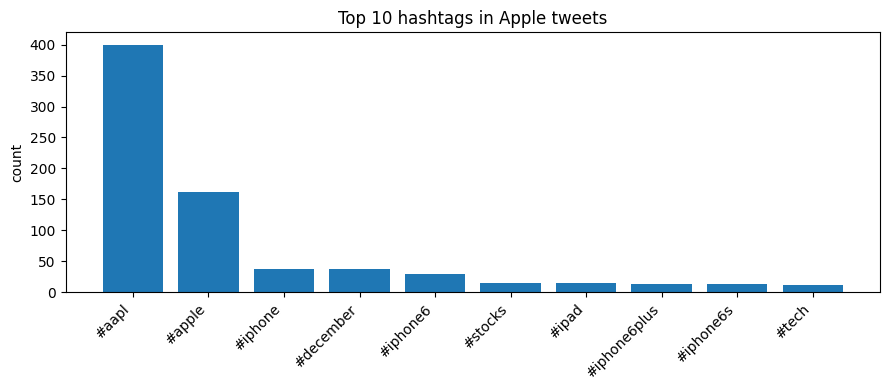

In [31]:
import matplotlib.pyplot as plt

tags, counts = zip(*top10)
plt.figure(figsize=(9, 4))
plt.bar(tags, counts)
plt.xticks(rotation=45, ha="right")
plt.title("Top 10 hashtags in Apple tweets")
plt.ylabel("count")
plt.tight_layout()
plt.show()

**Results**
- The dataset has **1,630 tweets**; **783** of them contain at least one hashtag, and **1,616 hashtags** are used in total.
- Top 10 hashtags: `#aapl` (400), `#apple` (162), `#iphone` (38), `#december` (37), `#iphone6` (29), `#stocks` (15), `#ipad` (14), `#iphone6plus` (13), `#iphone6s` (13), `#tech` (12).

**Why pre-processing matters here:** without lower-casing there are **607** different hashtags; after lower-casing only **555**. So 52 "different" hashtags were just the same tag in different capitalisation (e.g. `#Apple` / `#apple` / `#APPLE`), which would split their counts and give a wrong top-10.

# Task 2: Using re.compile()
Given the following text: "This year is 2021"

Write a Python program that:

1. Use re.compile() to create a regular expression pattern that matches one or more digits.
2. Print the type of the compiled pattern.
3. Use the compiled pattern to replace 2021 with 2022.
4. Print the updated text.
5. Briefly explain what re.compile() does and why it is useful when working with regular expressions.


### ✅ Solution – Task 2

In [32]:
import re

text = "This year is 2021"

# 1. compile a pattern that matches one or more digits
pattern = re.compile(r"\d+")

# 2. type of the compiled pattern
print(type(pattern))

# 3. use the compiled pattern to replace 2021 with 2022
updated_text = pattern.sub("2022", text)

# 4. print the updated text
print(updated_text)

<class 're.Pattern'>
This year is 2022


**5. What does `re.compile()` do and why is it useful?**

`re.compile()` turns a regular-expression string into a **pattern object** (`re.Pattern`).
The expression is parsed once and the object can then be reused through its own methods (`.search()`, `.findall()`, `.sub()`, `.split()` …).
This is useful when the same pattern is applied many times (e.g. to every row of a dataset): the pattern is defined in one place, the code is cleaner, and the expression is not re-parsed on every call.

# Task 3: Using re.split()
Given the following text = "a 11 b 2 3 c 4"

Write a Python program that:

1. Use re.split() with a regular expression pattern to split the text whenever one or more digits appear.
2. Print the resulting list.
3. Briefly explain: what re.split() does.


### ✅ Solution – Task 3

In [33]:
import re

text = "a 11 b 2 3 c 4"

# 1. split whenever one or more digits appear
result = re.split(r"\d+", text)

# 2. print the resulting list
print(result)

['a ', ' b ', ' ', ' c ', '']


**3. What does `re.split()` do?**

`re.split(pattern, string)` cuts the string **at every match of the pattern** and returns the pieces in between as a list; the matched text itself (here the digits) is dropped.
Unlike `str.split()`, which only splits on one fixed separator, `re.split()` can split on any pattern.
Note the empty string `''` at the end of the result: the text ends with a digit, so there is nothing after the last split point. The pieces also keep their surrounding spaces (`'a '`, `' b '`) because only the digits were used as the separator.

# Task 4: Tokenization Using spaCy

Processes the following sentence: "I'm enjoying the NLP course!"

Write a Python program that:

1. Use spaCy library and load the small English model en_core_web_sm.
2. Iterate through the text and print each token on a separate line.
3. Briefly explain: What spacy.load() does.
5. Tokenize the same text using nltk library and notice the differences compared to spaCy output.

### ✅ Solution – Task 4

In [34]:
import spacy

# 1. load the small English model
nlp = spacy.load("en_core_web_sm")

text = "I'm enjoying the NLP course!"
doc = nlp(text)

# 2. print each token on a separate line
for token in doc:
    print(token.text)

I
'm
enjoying
the
NLP
course
!


**3. What does `spacy.load()` do?**

`spacy.load("en_core_web_sm")` loads a trained spaCy **language pipeline** (here the *small English* model) and returns an `nlp` object.
That object contains the tokenizer plus trained components (POS tagger, dependency parser, NER, lemmatizer…). Calling `nlp(text)` runs the whole pipeline and returns a `Doc` – a sequence of `Token` objects with all their annotations.

In [35]:
# 5. Tokenize the same sentence with NLTK and compare
import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

spacy_tokens = [t.text for t in doc]
nltk_tokens = nltk.word_tokenize(text)

print("spaCy :", spacy_tokens)
print("NLTK  :", nltk_tokens)
print("Same tokens?", spacy_tokens == nltk_tokens)

# a harder sentence where the tokenizers disagree
hard = "Email me at test@mail.com, it costs $10.30 - don't wait!!! #NLP"
print("\nspaCy :", [t.text for t in nlp(hard)])
print("NLTK  :", nltk.word_tokenize(hard))

spaCy : ['I', "'m", 'enjoying', 'the', 'NLP', 'course', '!']
NLTK  : ['I', "'m", 'enjoying', 'the', 'NLP', 'course', '!']
Same tokens? True

spaCy : ['Email', 'me', 'at', 'test@mail.com', ',', 'it', 'costs', '$', '10.30', '-', 'do', "n't", 'wait', '!', '!', '!', '#', 'NLP']
NLTK  : ['Email', 'me', 'at', 'test', '@', 'mail.com', ',', 'it', 'costs', '$', '10.30', '-', 'do', "n't", 'wait', '!', '!', '!', '#', 'NLP']


**Differences between spaCy and NLTK**
- On `"I'm enjoying the NLP course!"` both tokenizers give the **same 7 tokens**: `I`, `'m`, `enjoying`, `the`, `NLP`, `course`, `!`. Both split the contraction and the punctuation (unlike `str.split()`, which would give `I'm` and `course!`).
- On the harder sentence they differ: **spaCy keeps the e-mail address `test@mail.com` as one token**, while **NLTK breaks it into `test`, `@`, `mail.com`**. Both split `don't` into `do` + `n't` and `$10.30` into `$` + `10.30`.
- The other difference is *what you get back*: NLTK returns plain strings, while spaCy returns `Token` objects that also carry the lemma, POS tag, stop-word flag, etc.